## 2026-10-27 기본 영상 처리 및 화면 표시, 행렬 기본 연산 
- 영상 읽기/쓰기
- matplotlib 사용법
- 행렬에 기본 연산 (5장)

In [18]:
# 공통부분
import sys
sys.path.append('../multi_info/common')
import cvnb
import cv2
import numpy as np

In [3]:
import numpy as np
image1 = cv2.imread("../multi_info/images/read_color.jpg", cv2.IMREAD_COLOR)
print(image1.dtype, image1.shape)
print(image1[0, 0:10])

uint8 (300, 400, 3)
[[187 132  87]
 [187 132  87]
 [187 132  87]
 [187 132  87]
 [187 132  87]
 [187 132  87]
 [187 132  87]
 [187 132  87]
 [186 131  88]
 [186 131  88]]


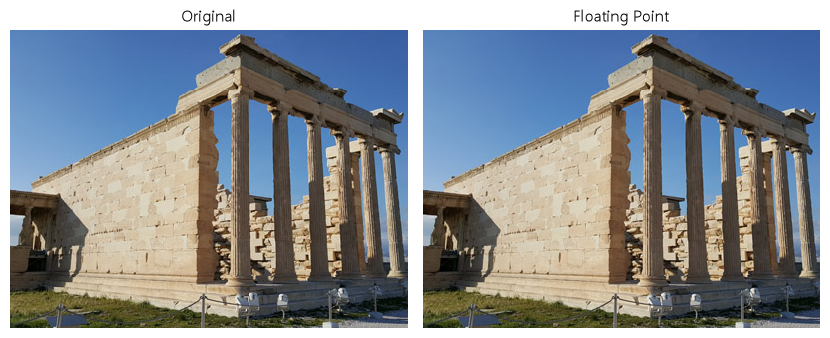

In [11]:
# 원래 저장된 형식을 기본으로 uint8로 읽습니다. 그런 다음 floating32 형식으로 변환하는 것 방식
# cv2.IMREAD_COLOR나 cv2.IMREAD_GRAYSCALE로 읽는 경우, 항상 CV_8U (uint8)로 변환해서 전달
# IMREAD_UNCHANGED나 IMREAD_ANYDEPTH가 있는 경우에는 원본의 형식으로 따름 (8/16/32F 등)

image2 = image1.astype(np.float32)/255.0

cv2.imshow("Original", image1)
cv2.imshow("Floating Point", image2)

In [5]:
print(image2[0, 0:10])

[[0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.73333335 0.5176471  0.34117648]
 [0.7294118  0.5137255  0.34509805]
 [0.7294118  0.5137255  0.34509805]]


In [6]:
image3 = cv2.imread("../multi_info/images/read_color.jpg", cv2.IMREAD_GRAYSCALE)
print(image3.shape, image3.dtype, image3[0, 0:10])

(300, 400) uint8 [125 125 125 125 125 125 125 125 124 124]


In [7]:
image4 = cv2.imread("../multi_info/images/read_gray.jpg", cv2.IMREAD_GRAYSCALE)
print(image4.shape, image4.dtype, image4[0, 0:10])

(300, 400) uint8 [93 93 93 93 93 93 93 92 92 92]


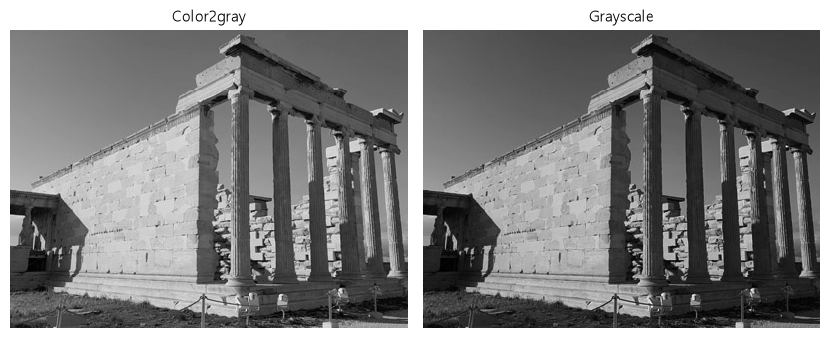

In [8]:
cv2.imshow("Color2gray", image3)
cv2.imshow("Grayscale", image4)

(300, 400, 3) uint8 [[93 93 93]
 [93 93 93]
 [93 93 93]
 [93 93 93]
 [93 93 93]
 [93 93 93]
 [93 93 93]
 [92 92 92]
 [92 92 92]
 [92 92 92]]


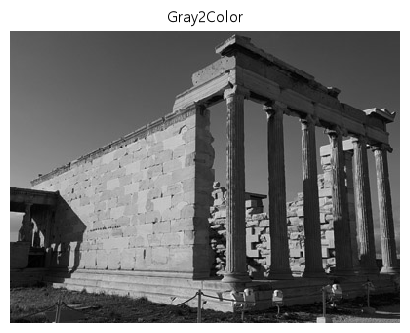

In [9]:
image5 = cv2.imread("../multi_info/images/read_gray.jpg", cv2.IMREAD_COLOR)
print(image5.shape, image5.dtype, image5[0, 0:10])
cv2.imshow("Gray2Color", image5)

## Video 파일 읽기

In [34]:
# cvnb import 없이 사용할 것
import cv2
capture = cv2.VideoCapture("../multi_info/images/movie_file.avi")
count = 0
while True:
    ret, frame = capture.read()
    if not ret: break
    count += 1
    if count%2 != 0: continue
    if cv2.waitKey(30) >= 0: break
    cv2.imshow("Video", frame)
capture.release()
cv2.destroyAllWindows()


# matplotlib를 이용한 그림 / 표 그리기

(300, 240, 3) uint8 [[185 188 186]
 [187 190 188]
 [183 186 184]
 [180 183 181]
 [184 187 185]
 [185 188 186]
 [181 184 182]
 [179 182 180]
 [175 177 177]
 [174 176 176]]


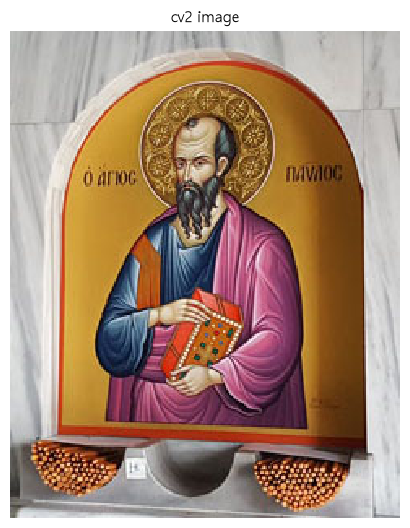

In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imdecode(np.fromfile("../multi_info/images/matplot.jpg", dtype=np.uint8), cv2.IMREAD_COLOR)

if image is None:
    raise Exception("영상 파일 읽기 에러")

print(image.shape, image.dtype, image[0,0:10])
cv2.imshow("cv2 image", image)

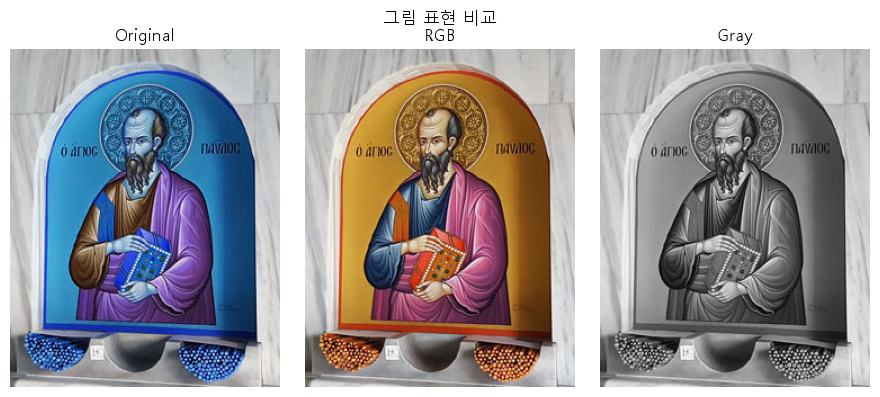

In [42]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path.cwd()

paths = [
    folder / "multi_info/images/matplot.jpg",
    folder.parent / "multi_info/images/matplot.jpg"
]

image_path = next((p for p in paths if p.is_file()), None)

if image_path is None:
    raise Exception("이미지 파일을 찾을 수 없습니다.")

image = cv2.imdecode(
    np.fromfile(str(image_path), dtype=np.uint8),
    cv2.IMREAD_COLOR
)

if image is None:
    raise Exception("영상 파일 읽기 에러")

rgb_img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray_img = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

fig = plt.figure(figsize=(9, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(rgb_img)
plt.title("RGB")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Gray")
plt.imshow(gray_img, cmap='gray')
plt.axis('off')

plt.suptitle("그림 표현 비교")
plt.tight_layout()
plt.show()

[0 1 2 3 4 5 6 7 8 9] [0 1 2 3 4 5 6 7 8 9] [ 0  1  4  9 16 25 36 49 64 81] [ 7 23 17 25 49 30 35 32 43  2]


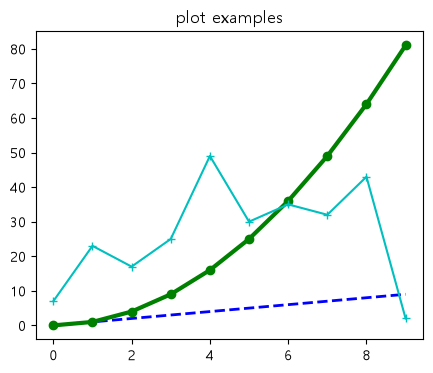

In [47]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(10)
y1 = np.arange(10) # linear
y2 = y1 ** 2 # 2차
y3 = np.random.choice(50, size=10)

print(x, y1, y2, y3)

plt.figure(figsize=(5,4))
plt.plot(x, y1, "b--", linewidth=2)
plt.plot(x, y2, "go-", linewidth=3)
plt.plot(x, y3, "c+-")
#plt.axis([25, 6, 20, 50])
plt.title("plot examples")

plt.show()